# Online Retail Analysis: Sales, Customers and Returns

**Author:** Komal Sargar  |  **Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

## Goal
Clean a year of transaction data from an online gift retailer and answer four business questions:
1. **Sales:** when, where and what sells the most?
2. **Customers:** who brings in the revenue, and who is drifting away?
3. **Retention:** do customers come back after their first purchase?
4. **Returns:** which products are cancelled most, and when?

## Data source
*Online Retail* dataset (UCI Machine Learning Repository): every transaction of a UK-based online retailer between **1 Dec 2010 and 9 Dec 2011**. It has **541,909 rows and 8 columns** (InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country). Values are in GBP.

## Contents
1. Load and inspect the data
2. Data cleaning
3. Sales analysis
4. Customer analysis (Pareto, RFM, cohort retention)
5. Cleaning summary
6. Returns analysis
7. Findings, recommendations and limitations

## 1. Load and inspect the data
Import the libraries, load the Excel file and check its size, data types, missing values and duplicates before changing anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

# Load the Excel file into a DataFrame
df = pd.read_excel(r"Online Retail.xlsx")

In [3]:
# Preview the first 5 rows of data
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(5268)

**What the inspection shows:** 541,909 rows; 1,454 rows have no `Description`; about 25% of rows have no `CustomerID` (406,829 of 541,909 are filled); and 5,268 rows are exact duplicates. The minimum `Quantity` (-80,995) and `UnitPrice` (-11,062) are negative, which points to cancellations and adjustments that must be handled in the cleaning step.

## 2. Data cleaning
Work on a copy (`data`) so the original `df` stays untouched. Each step is checked with a row count so nothing is removed silently:

| Step | Decision | Why |
|---|---|---|
| 1 | Drop rows with no `Description` | Cannot tell which product was sold |
| 2 | Keep rows with no `CustomerID`, add a `Customer_Known` flag | They are real sales. They are excluded only from customer-level analysis |
| 3 | Fix data types | Dates as datetime, `InvoiceNo` as text (cancelled invoices start with "C"), `CustomerID` as text |
| 4 | Remove duplicate rows | Same row recorded twice |
| 5 | Move cancelled invoices ("C...") into a separate `returns` table | Needed for the returns analysis, but they should not count as sales |
| 6 | Remove `Quantity <= 0` or `UnitPrice <= 0` | Adjustments and free or test entries, not real sales |
| 7 | Remove non-product codes (postage, discounts, manual entries) | They are not products. Only real product codes (starting with 5 digits) are kept |

In [9]:
data = df.copy()

In [10]:
data = data.dropna(subset=["Description"])

In [11]:
data["Customer_Known"] = data["CustomerID"].notnull()

In [12]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])   # text to date
data["InvoiceNo"] = data["InvoiceNo"].astype(str)           # text, because cancelled invoices start with "C"
data["CustomerID"] = data["CustomerID"].astype("Int64")     # whole number, blanks stay blank

In [13]:
data.info()

<class 'pandas.DataFrame'>
Index: 540455 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   InvoiceNo       540455 non-null  str           
 1   StockCode       540455 non-null  object        
 2   Description     540455 non-null  object        
 3   Quantity        540455 non-null  int64         
 4   InvoiceDate     540455 non-null  datetime64[us]
 5   UnitPrice       540455 non-null  float64       
 6   CustomerID      406829 non-null  Int64         
 7   Country         540455 non-null  str           
 8   Customer_Known  540455 non-null  bool          
dtypes: Int64(1), bool(1), datetime64[us](1), float64(1), int64(1), object(2), str(2)
memory usage: 38.1+ MB


Cell 13 repeats the work of cells 9 and 10 (dropping missing descriptions and adding the flag). It is harmless because running it twice gives the same result, so it is left as it was.

In [14]:
data = data.dropna(subset=["Description"])
data["Customer_Known"] = data["CustomerID"].notnull()

In [15]:
data.isnull().sum()

InvoiceNo              0
StockCode              0
Description            0
Quantity               0
InvoiceDate            0
UnitPrice              0
CustomerID        133626
Country                0
Customer_Known         0
dtype: int64

In [16]:
data.duplicated().sum()

np.int64(5268)

In [17]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 5268


In [18]:
data = data.drop_duplicates()
print("Rows left:", len(data))

Rows left: 535187


5,268 exact duplicate rows removed. **Rows left: 535,187.**

In [19]:
data["InvoiceNo"] = data["InvoiceNo"].astype(str)          # make sure it's text
data[data["InvoiceNo"].str.startswith("C")].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Customer_Known
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom,True
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom,True
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom,True
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,True
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,True


In [20]:
returns = data[data["InvoiceNo"].str.startswith("C")]      # cancelled invoices
data = data[~data["InvoiceNo"].str.startswith("C")]        # everything else = sales

print("Cancelled rows:", len(returns))
print("Sales rows left:", len(data))

Cancelled rows: 9251
Sales rows left: 525936


9,251 cancelled rows were moved to `returns`. **525,936 sales rows left.**

In [21]:
data["Quantity"].min()

np.int64(-9600)

In [22]:
print("Quantity <= 0:", (data["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (data["UnitPrice"] <= 0).sum())

Quantity <= 0: 474
UnitPrice <= 0: 1058


In [23]:
data = data[(data["Quantity"] > 0) & (data["UnitPrice"] > 0)]
print("Rows left:", len(data))

Rows left: 524878


1,058 rows with a zero or negative price (or quantity) removed. **524,878 rows left.**

In [24]:
data["StockCode"] = data["StockCode"].astype(str).str.strip().str.upper()
not_products = data[~data["StockCode"].str.match(r"^\d{5}")]
not_products["StockCode"].value_counts().head(10)

StockCode
POST            1126
DOT              706
M                317
C2               141
DCGSSGIRL         13
BANK CHARGES      12
DCGSSBOY          11
GIFT_0001_20       9
GIFT_0001_10       8
GIFT_0001_30       7
Name: count, dtype: int64

In [25]:
data = data[data["StockCode"].str.match(r"^\d{5}")]
print("Rows left:", len(data))

Rows left: 522504


2,374 non-product rows removed (for example `POST` for postage, `DOT` for dotcom postage, `M` for manual entries). **522,504 rows left** (96.4% of the original data).

In [26]:
data["Quantity"].min()
data["UnitPrice"].min()

np.float64(0.04)

**Feature engineering:** the next cell creates `Revenue = Quantity × UnitPrice`, plus `Date`, `Month`, `Weekday` and `Hour`, which the charts below use.

In [27]:
data["Revenue"] = data["Quantity"] * data["UnitPrice"]

In [28]:
data["Date"] = data["InvoiceDate"].dt.date
data["Month"] = data["InvoiceDate"].dt.to_period("M")     # for example 2011-03
data["Weekday"] = data["InvoiceDate"].dt.day_name()       # Monday, Tuesday...
data["Hour"] = data["InvoiceDate"].dt.hour                # 0 to 23

In [29]:
data[["InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Month", "Weekday", "Hour"]].head()

,InvoiceDate,Quantity,UnitPrice,Revenue,Month,Weekday,Hour
0,2010-12-01 08:26:00,6,2.55,15.30,2010-12,Wednesday,8
1,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8
2,2010-12-01 08:26:00,8,2.75,22.00,2010-12,Wednesday,8
3,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8
4,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8


In [30]:
data = data.reset_index(drop=True)

In [31]:
print("Total revenue:", round(data["Revenue"].sum(), 2))
print("Number of orders:", data["InvoiceNo"].nunique())
print("Number of customers:", data["CustomerID"].nunique())
print("Average order value:", round(data["Revenue"].sum() / data["InvoiceNo"].nunique(), 2))

Total revenue: 10246820.87
Number of orders: 19773
Number of customers: 4334
Average order value: 518.22


**Headline numbers from the clean data:** total revenue **10,246,820.87**, **19,773 orders** and **4,334 identified customers**. Average order value is **518.22**. The clean data is saved to `online_retail_cleaned.csv` for later use (for example in Power BI).

In [32]:
data.to_csv("online_retail_cleaned.csv", index=False)

## 3. Sales analysis
### 3.1 Monthly revenue

In [33]:
monthly = data.groupby("Month")["Revenue"].sum()
print(monthly)

Month
2010-12     775572.23
2011-01     670361.99
2011-02     507783.42
2011-03     689708.49
2011-04     515354.78
2011-05     739914.35
2011-06     737558.98
2011-07     688144.79
2011-08     724196.76
2011-09    1028313.80
2011-10    1103310.96
2011-11    1452112.69
2011-12     614487.63
Freq: M, Name: Revenue, dtype: float64


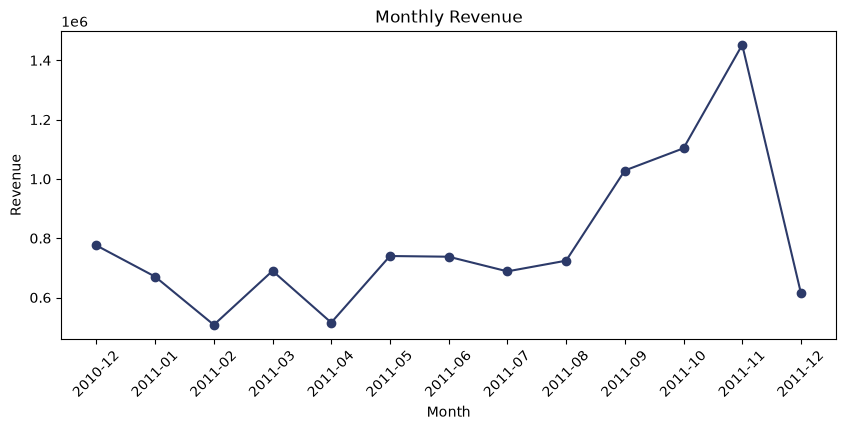

In [34]:
monthly.index = monthly.index.astype(str)       # turns 2011-03 into text so the chart can label it

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker="o", color="#2C3A69")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.savefig("monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()


**Reading the chart:** revenue is fairly flat from December 2010 to August 2011 (about 0.5M to 0.78M a month), then climbs sharply from September and peaks in **November 2011 at 1.45M**, which is almost double the typical spring month. This is the pre-Christmas season for a gift retailer. December 2011 looks like a drop, but the data ends on **9 December**, so that month is incomplete and should not be read as a decline.

### 3.2 Top products

In [35]:
product_revenue = data.groupby("Description")["Revenue"].sum()
top10 = product_revenue.sort_values(ascending=False).head(10)
print(top10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64


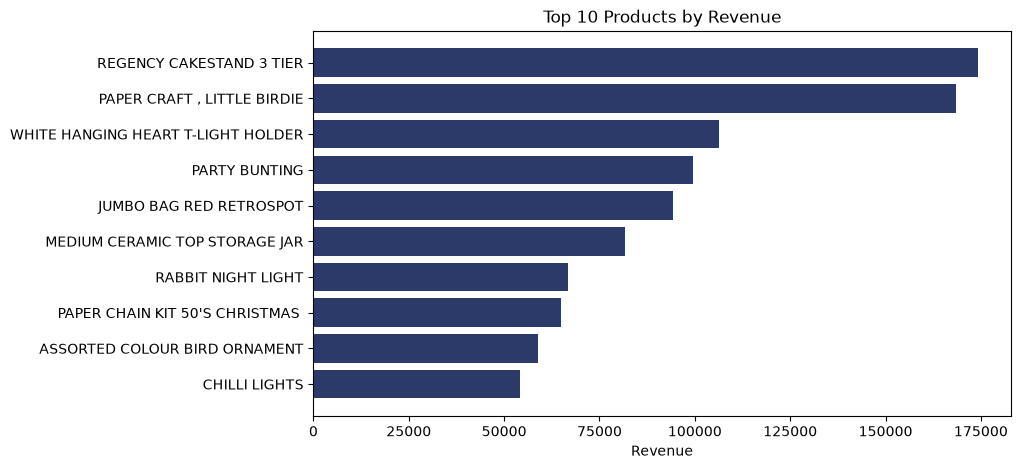

In [36]:
top10 = top10.sort_values()          # smallest first, so the biggest bar ends up on top

plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10.values, color="#2C3A69")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.savefig("top10_products.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** the best sellers are *Regency Cakestand 3 Tier* (174,157), *Paper Craft, Little Birdie* (168,470) and *White Hanging Heart T-Light Holder* (106,237). The top 10 products together bring in about 9.5% of revenue, so sales are spread over many products rather than a few.

**Check before using this chart:** *Paper Craft, Little Birdie* equals exactly 80,995 units × 2.08, and the data contains a single order of 80,995 units that was later cancelled (see section 6). The cancelled invoice was removed, but the original sale stayed in, so this product's revenue is almost certainly overstated. The same applies to *Medium Ceramic Top Storage Jar*, whose 74,000+ returned units appear in the returns chart.

### 3.3 Revenue by country

85.1 % of revenue from United Kingdom


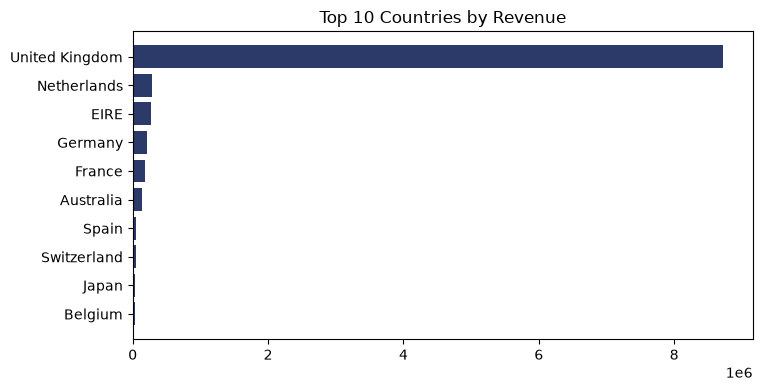

In [37]:
country = data.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
print(round(country.iloc[0] / country.sum() * 100, 1), "% of revenue from", country.index[0])

top_c = country.head(10).sort_values()
plt.figure(figsize=(8, 4))
plt.barh(top_c.index, top_c.values, color="#2C3A69")
plt.title("Top 10 Countries by Revenue")
plt.savefig("country_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** the **United Kingdom brings 85.1% of revenue**, so it dominates the chart.

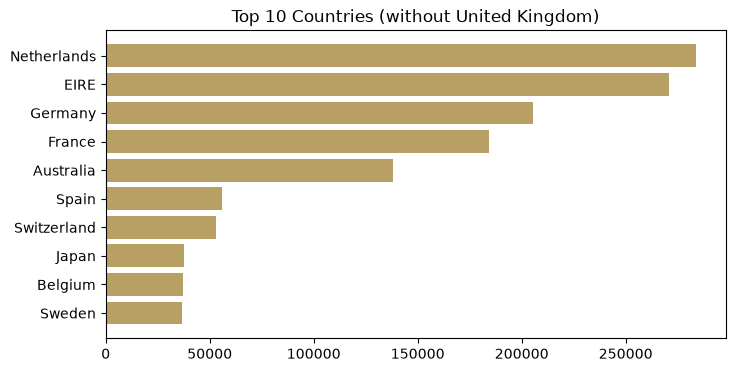

In [38]:
other = country.drop("United Kingdom").head(10).sort_values()
plt.figure(figsize=(8, 4))
plt.barh(other.index, other.values, color="#B8A064")
plt.title("Top 10 Countries (without United Kingdom)")
plt.savefig("country_revenue_no_uk.png", dpi=150, bbox_inches="tight")
plt.show()

**Without the UK:** the next markets are the Netherlands and EIRE (Ireland), each at roughly 270,000 to 285,000, followed by Germany (about 205,000), France (about 185,000) and Australia (about 138,000). Spain, Switzerland, Japan, Belgium and Sweden are all below 60,000.

### 3.4 When do customers order? (weekday × hour)

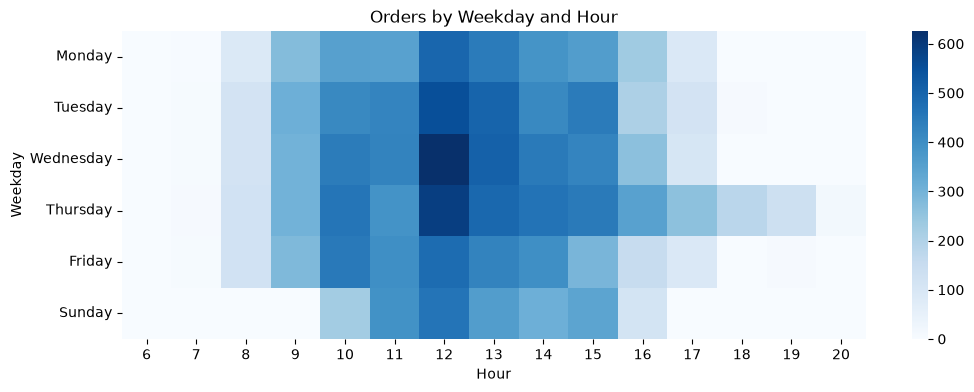

In [39]:
orders = data.drop_duplicates("InvoiceNo")      # one row per order
table = orders.pivot_table(index="Weekday", columns="Hour", values="InvoiceNo", aggfunc="count", fill_value=0)

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
table = table.reindex([d for d in days if d in table.index])    # puts the days in order

plt.figure(figsize=(12, 4))
sns.heatmap(table, cmap="Blues")
plt.title("Orders by Weekday and Hour")
plt.savefig("weekday_hour.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the heatmap:** each cell is the number of orders. Ordering is concentrated between **10:00 and 15:00**, with the busiest slot on **Wednesday and Thursday around 12:00** (about 600 orders). Thursday is the only day with a noticeable evening tail (17:00 to 19:00). Sunday starts later and is lighter. There are **no orders at all on Saturday** in this dataset, so that row is missing from the chart.

### 3.5 Order value

Mean: 518.22  Median: 302.2


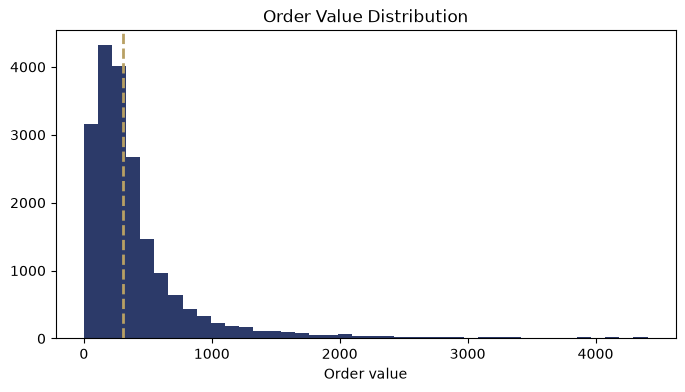

In [40]:
order_value = data.groupby("InvoiceNo")["Revenue"].sum()
print("Mean:", round(order_value.mean(), 2), " Median:", round(order_value.median(), 2))

clipped = order_value[order_value < order_value.quantile(0.99)]   # hides a few huge orders so the chart is readable

plt.figure(figsize=(8, 4))
plt.hist(clipped, bins=40, color="#2C3A69")
plt.axvline(order_value.median(), color="#B8A064", linestyle="--", linewidth=2)
plt.title("Order Value Distribution")
plt.xlabel("Order value")
plt.savefig("order_value.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** most orders are small. The **median order is 302.20**, while the **mean is 518.22**, so a small number of very large orders pull the average up. (The chart hides the top 1% of orders so the main shape stays visible.) For typical order size, the median is the more honest number.

## 4. Customer analysis
Only rows with a known `CustomerID` are used in this section (about 75% of rows).

### 4.1 How concentrated is revenue? (Pareto)

Top 20% of customers bring 74.6 % of revenue


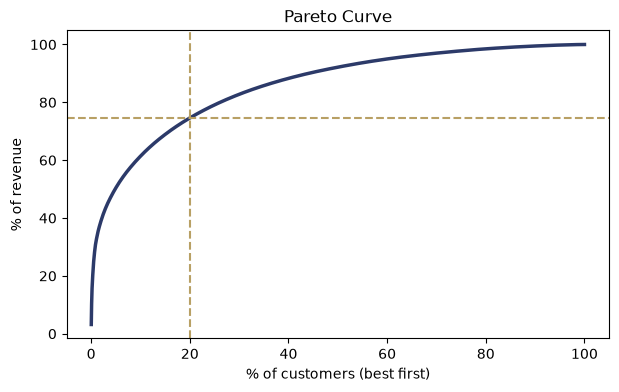

In [41]:
known = data[data["Customer_Known"]]       # only rows that have a customer ID

cust = known.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
cum_share = cust.cumsum() / cust.sum() * 100
pct_customers = np.arange(1, len(cust) + 1) / len(cust) * 100

top20 = cum_share.iloc[int(len(cust) * 0.2) - 1]
print("Top 20% of customers bring", round(top20, 1), "% of revenue")

plt.figure(figsize=(7, 4))
plt.plot(pct_customers, cum_share.values, color="#2C3A69", linewidth=2.5)
plt.axvline(20, color="#B8A064", linestyle="--")
plt.axhline(top20, color="#B8A064", linestyle="--")
plt.xlabel("% of customers (best first)")
plt.ylabel("% of revenue")
plt.title("Pareto Curve")
plt.savefig("pareto.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** the **top 20% of customers bring 74.6% of revenue**, which is close to the classic 80/20 rule. Losing a few top customers would hurt much more than losing many small ones.

### 4.2 RFM segmentation
Each customer is scored from 1 to 5 on **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** (total spend). Scores are then grouped into six segments.

In [42]:
snapshot = known["InvoiceDate"].max() + pd.Timedelta(days=1)       # "today" for the analysis
last_purchase = known.groupby("CustomerID")["InvoiceDate"].max()

rfm = pd.DataFrame({
    "Recency": (snapshot - last_purchase).dt.days,
    "Frequency": known.groupby("CustomerID")["InvoiceNo"].nunique(),
    "Monetary": known.groupby("CustomerID")["Revenue"].sum(),
})

In [43]:
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [44]:
conditions = [
    (rfm["R"] >= 4) & (rfm["F"] >= 4),
    (rfm["R"] >= 3) & (rfm["F"] >= 3),
    (rfm["R"] >= 4) & (rfm["F"] <= 2),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2) & (rfm["F"] <= 2),
]
names = ["Champions", "Loyal", "New / Promising", "At Risk", "Hibernating"]
rfm["Segment"] = np.select(conditions, names, default="Needs Attention")

                 Customers    Revenue  Customer_%  Revenue_%
Segment                                                     
New / Promising        310   139347.6         7.2        1.6
Needs Attention        346   156442.3         8.0        1.8
Hibernating           1078   515889.9        24.9        5.9
At Risk                656   810718.0        15.1        9.3
Loyal                  824  1337623.8        19.0       15.3
Champions             1120  5777206.0        25.8       66.1


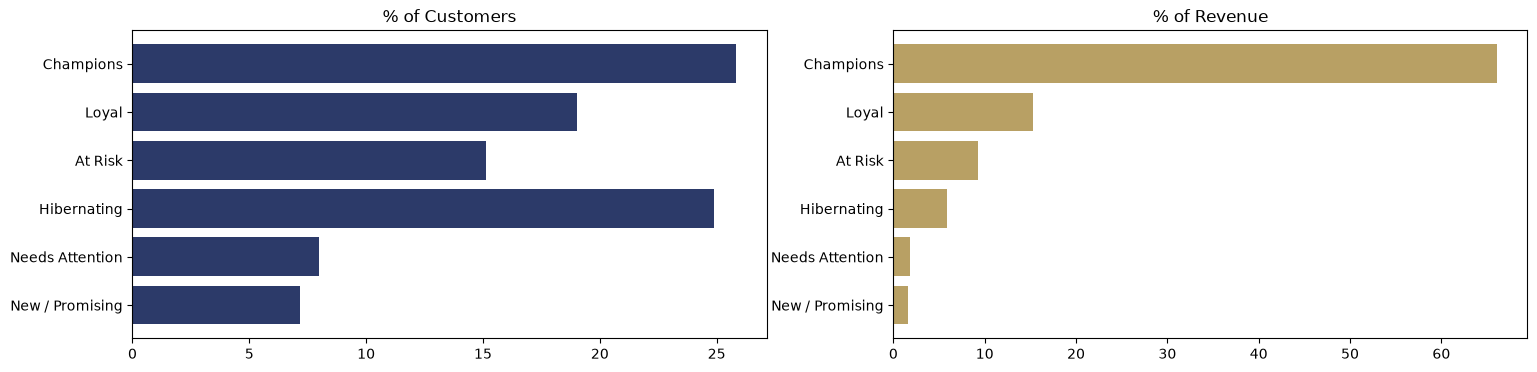

In [45]:
segments = rfm.groupby("Segment").agg(Customers=("Monetary", "size"), Revenue=("Monetary", "sum"))
segments["Customer_%"] = segments["Customers"] / segments["Customers"].sum() * 100
segments["Revenue_%"] = segments["Revenue"] / segments["Revenue"].sum() * 100
segments = segments.sort_values("Revenue_%")
print(segments.round(1))

fig, axes = plt.subplots(1, 2, figsize=(18, 4))
axes[0].barh(segments.index, segments["Customer_%"], color="#2C3A69")
axes[0].set_title("% of Customers")
axes[1].barh(segments.index, segments["Revenue_%"], color="#B8A064")
axes[1].set_title("% of Revenue")
plt.savefig("rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:**

| Segment | Customers | % of customers | % of revenue |
|---|---|---|---|
| Champions | 1,120 | 25.8% | 66.1% |
| Loyal | 824 | 19.0% | 15.3% |
| At Risk | 656 | 15.1% | 9.3% |
| Hibernating | 1,078 | 24.9% | 5.9% |
| Needs Attention | 346 | 8.0% | 1.8% |
| New / Promising | 310 | 7.2% | 1.6% |

**Champions are about a quarter of customers but two thirds of revenue.** At Risk customers (656) were once good buyers who have gone quiet, and their past spend of about 811,000 makes them the best group to win back.

### 4.3 Cohort retention
Customers are grouped by the month of their **first purchase** (rows). Each cell shows the share of that group who ordered again N months later (columns).

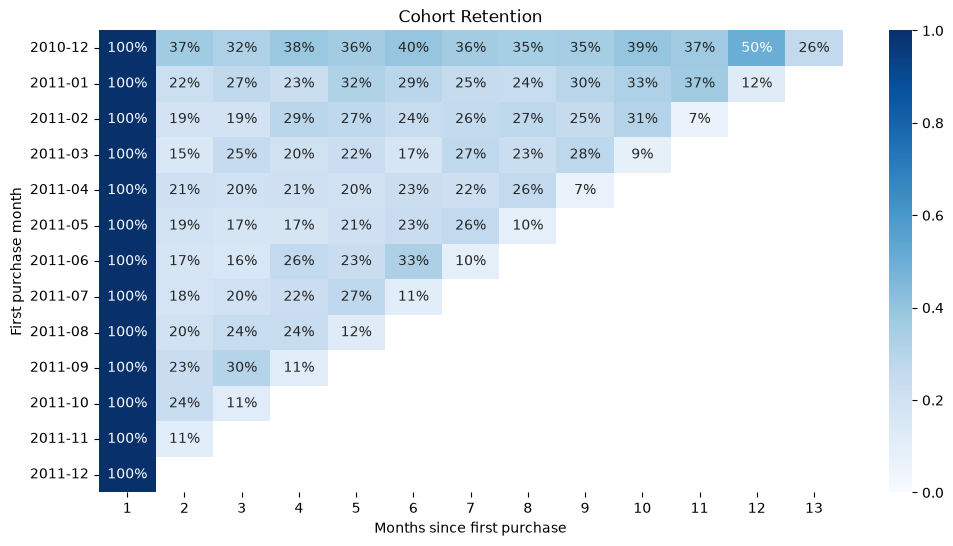

In [46]:
known = known.copy()
known["OrderMonth"] = known["InvoiceDate"].dt.to_period("M")
first_purchase = known.groupby("CustomerID")["InvoiceDate"].transform("min")
known["CohortMonth"] = first_purchase.dt.to_period("M")

known["MonthNumber"] = ((known["OrderMonth"].dt.year - known["CohortMonth"].dt.year) * 12
                        + (known["OrderMonth"].dt.month - known["CohortMonth"].dt.month) + 1)

cohort = known.groupby(["CohortMonth", "MonthNumber"])["CustomerID"].nunique().unstack()
retention = cohort.divide(cohort[1], axis=0)        # divide by month-1 customers
retention.index = retention.index.astype(str)

plt.figure(figsize=(12, 6))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.xlabel("Months since first purchase")
plt.ylabel("First purchase month")
plt.title("Cohort Retention")
plt.savefig("cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the heatmap:** the **December 2010 cohort is by far the strongest**, with 32% to 50% of customers returning in almost every later month (50% in month 12). For the 2011 cohorts, only about **15% to 24% come back in month 2**, and most later months stay between roughly 17% and 33%. Retention is steady rather than collapsing, but about 8 in 10 new customers do not return the next month. The last cohorts (November and December 2011) show low values only because the data stops on 9 December.

## 5. Cleaning summary
### 5.1 Missing values in the raw data

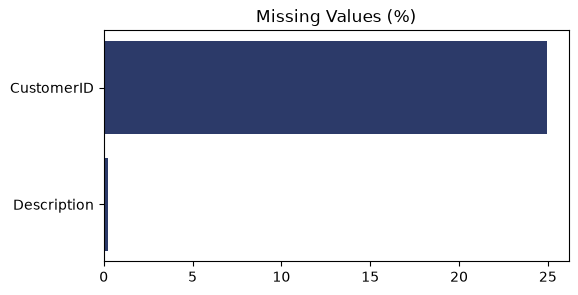

In [47]:
missing = df.isnull().sum() / len(df) * 100
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(6, 3))
plt.barh(missing.index, missing.values, color="#2C3A69")
plt.title("Missing Values (%)")
plt.savefig("missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

`CustomerID` is missing in about 25% of rows and `Description` in about 0.3%. This is why customer-level analysis uses only about three quarters of the data.

### 5.2 Rows removed at each cleaning step
The numbers below were filled in from the row counts printed in section 2 (they were placeholders before).

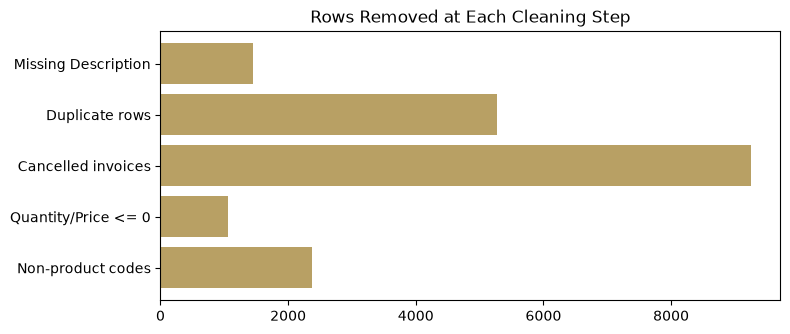

In [48]:
removed = {
    "Missing Description": 1454,
    "Duplicate rows": 5268,
    "Cancelled invoices": 9251,
    "Quantity/Price <= 0": 1058,
    "Non-product codes": 2374,
}

plt.figure(figsize=(8, 3.5))
plt.barh(list(removed.keys()), list(removed.values()), color="#B8A064")
plt.gca().invert_yaxis()
plt.title("Rows Removed at Each Cleaning Step")
plt.savefig("cleaning_log.png", dpi=150, bbox_inches="tight")
plt.show()

Total removed: **19,405 rows (3.6%)**, leaving 522,504 of 541,909. Cancelled invoices are the largest group (9,251 rows) but are not discarded: they are kept in `returns` for the next section.

## 6. Returns analysis
Cancelled invoices (those starting with "C") are analysed separately from sales.

### 6.1 Cancelled invoices by month

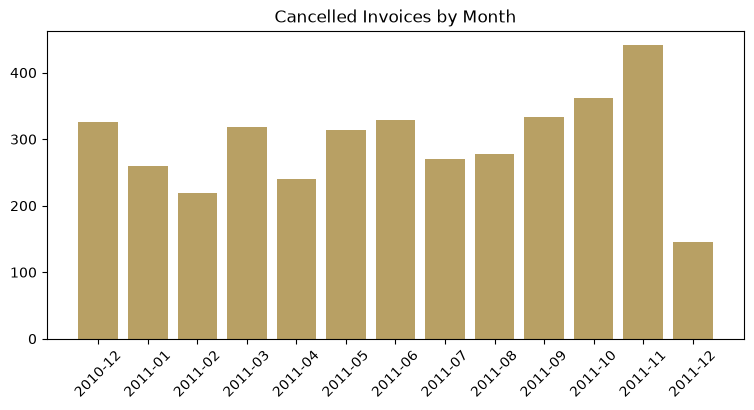

In [49]:
returns = returns.copy()
returns["Month"] = returns["InvoiceDate"].dt.to_period("M").astype(str)

by_month = returns.groupby("Month")["InvoiceNo"].nunique()

plt.figure(figsize=(9, 4))
plt.bar(by_month.index, by_month.values, color="#B8A064")
plt.xticks(rotation=45)
plt.title("Cancelled Invoices by Month")
plt.savefig("returns_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** roughly **220 to 440 invoices are cancelled every month**. The peak is **November 2011 (about 440)**, the same month as the sales peak, so more orders also means more cancellations. December 2011 is lower only because the data ends on 9 December.

### 6.2 Most returned products

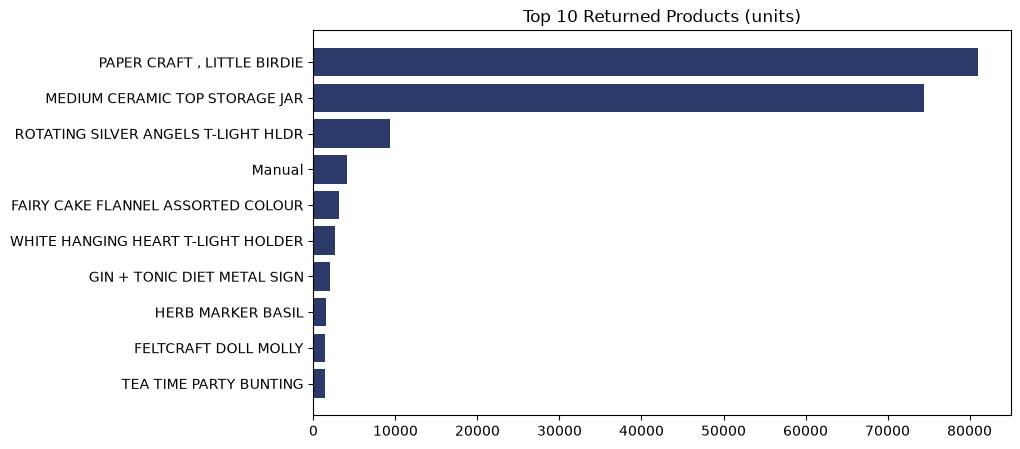

In [50]:
returned = returns.groupby("Description")["Quantity"].sum().abs().sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(returned.index, returned.values, color="#2C3A69")
plt.title("Top 10 Returned Products (units)")
plt.savefig("top_returned.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** two products dominate: *Paper Craft, Little Birdie* (about 81,000 units) and *Medium Ceramic Top Storage Jar* (about 74,000 units). Every other product is below 10,000 units. These two are single huge orders that were cancelled, not a steady pattern of customers returning goods. Excluding them, the most returned items are small: *Rotating Silver Angels T-Light Holder* (about 9,000), *Manual* (about 4,000) and *Fairy Cake Flannel Assorted Colour* (about 3,000).

## 7. Findings, recommendations and limitations

### Key findings
1. **Sales are seasonal.** Revenue is flat at 0.5M to 0.78M a month until August, then rises to a peak of **1.45M in November 2011**.
2. **Revenue comes mostly from the UK.** The United Kingdom is **85.1%** of revenue. The next markets are the Netherlands, EIRE, Germany, France and Australia.
3. **Revenue is concentrated in few customers.** The top 20% of customers bring **74.6%** of revenue. **Champions are 25.8% of customers but 66.1% of revenue.**
4. **Many customers are fading.** 656 customers are *At Risk* and 1,078 are *Hibernating* (together 40% of customers).
5. **Retention is modest.** In 2011, about 15% to 24% of new customers return in their second month. The December 2010 cohort is the exception, with 32% to 50% returning each month.
6. **Orders are placed at midday on weekdays.** The peak is Wednesday and Thursday around 12:00; there are no Saturday orders.
7. **Typical order value is 302.20 (median)**, well below the 518.22 mean because of a few very large orders.
8. **Two huge cancelled orders distort product figures.** Paper Craft, Little Birdie and Medium Ceramic Top Storage Jar rank high in revenue and in returns because of single bulk orders.

### Recommendations
1. **Plan stock and staff for September to November**, with extra capacity for the November peak (and for the higher number of cancellations that month).
2. **Protect Champions** with early access, loyalty rewards or a dedicated contact, since they carry two thirds of revenue.
3. **Run a win-back campaign for the 656 At Risk customers**, who have about 811,000 in past spend, before they move to Hibernating.
4. **Improve the second purchase.** A follow-up offer in the first month could lift the 15% to 24% month-2 return rate.
5. **Test the weekday-midday window** for promotions, emails and customer support, and check why there are no Saturday orders (a business rule or a data issue).
6. **Treat large cancelled orders separately.** Match each cancellation to its original sale so that revenue and top-product rankings are not overstated.
7. **Look at the Netherlands, EIRE and Germany first** if the business wants to grow outside the UK, as they are already the largest export markets.

### Limitations
- **Customer analysis covers only about 75% of rows.** About 25% of transactions have no `CustomerID` and are excluded from RFM, Pareto and cohort analysis.
- **The period is one year** (1 Dec 2010 to 9 Dec 2011). December 2011 is incomplete, and no year-on-year comparison is possible.
- **Cancellations are not matched to original sales.** Cancelled invoices were removed from the sales data without removing the sales they cancel, so revenue, and especially the top-product ranking, is slightly overstated (the two bulk orders alone are about 245,000, or roughly 2.4% of revenue).
- **No cost or profit data.** Revenue is not profit, so product and customer value is judged on sales only.
- **RFM thresholds are rule-based.** The segment names depend on the score cut-offs chosen in this notebook, so another reasonable rule would move some customers between segments.
- **Cohort retention is based on any purchase in a month**, not on purchase value.